In [1]:
import pandas as pd

load_column = "SE_3_load_actual_entsoe_transparency"

demand = pd.read_csv(
    "data/time_series_60min_singleindex.csv",
    usecols=["utc_timestamp", load_column],
).rename(columns={load_column: "demand_mw"})

demand["utc_timestamp"] = pd.to_datetime(demand["utc_timestamp"], utc=True)
demand = demand.sort_values("utc_timestamp").set_index("utc_timestamp")

print("Date range:", demand.index.min(), "to", demand.index.max())
print("Missing demand values:", demand["demand_mw"].isna().sum())
print("Duplicate timestamps:", demand.index.duplicated().sum())
print(demand.head())

Date range: 2014-12-31 23:00:00+00:00 to 2020-09-30 23:00:00+00:00
Missing demand values: 80
Duplicate timestamps: 0
                           demand_mw
utc_timestamp                       
2014-12-31 23:00:00+00:00        NaN
2015-01-01 00:00:00+00:00        NaN
2015-01-01 01:00:00+00:00     9277.0
2015-01-01 02:00:00+00:00     9132.0
2015-01-01 03:00:00+00:00     9083.0


In [2]:
print("Total rows:", len(demand))
print("Missing demand readings:", demand["demand_mw"].isna().sum())
print("Duplicate timestamps:", demand.index.duplicated().sum())

Total rows: 50401
Missing demand readings: 80
Duplicate timestamps: 0


In [3]:
january = demand.loc["2019-01", "demand_mw"]

print("January rows:", len(january))
print("Missing January readings:", january.isna().sum())

January rows: 744
Missing January readings: 0


<Axes: title={'center': 'SE3 daily average electricity demand — January 2019'}, xlabel='Date (UTC)', ylabel='Demand (MW)'>

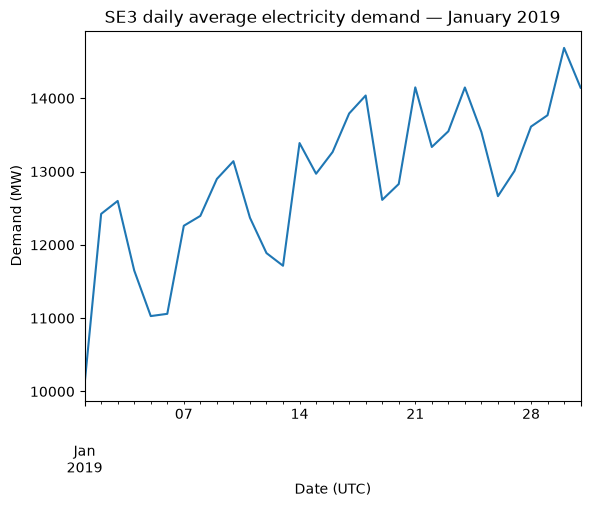

In [4]:
january.resample("D").mean().plot(
    title="SE3 daily average electricity demand — January 2019",
    xlabel="Date (UTC)",
    ylabel="Demand (MW)",
)

### Daily electricity demand in SE3 — January 2019

The chart shows how electricity demand varied from day to day in Sweden’s SE3 bidding zone. Each point is the average of the hourly demand readings for one UTC day, measured in megawatts (MW).
Average demand was highest on Jan 30 and lowest on Jan 1.

In [6]:
# Calculate daily averages using days with 24 valid hourly readings
by_day = january.resample("D")
daily = by_day.mean()[by_day.count().eq(24)]

weekday_mean = daily[daily.index.dayofweek < 5].mean()
weekend_mean = daily[daily.index.dayofweek >= 5].mean()
weekend_change = 100 * (weekend_mean / weekday_mean - 1)

print(f"Lowest daily average: {daily.min():,.0f} MW on {daily.idxmin():%d %b}")
print(f"Highest daily average: {daily.max():,.0f} MW on {daily.idxmax():%d %b}")
print(f"Peak-to-trough difference: {daily.max() - daily.min():,.0f} MW")
print(f"Weekday average: {weekday_mean:,.0f} MW")
print(f"Weekend average: {weekend_mean:,.0f} MW")
print(f"Weekend change relative to weekdays: {weekend_change:+.1f}%")

Lowest daily average: 10,103 MW on 01 Jan
Highest daily average: 14,687 MW on 30 Jan
Peak-to-trough difference: 4,584 MW
Weekday average: 13,140 MW
Weekend average: 12,101 MW
Weekend change relative to weekdays: -7.9%


C:\Users\nezha\AppData\Local\Temp\ipykernel_8204\1583895190.py:5: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  weekday_mean = daily[daily.index.dayofweek < 5].mean()
C:\Users\nezha\AppData\Local\Temp\ipykernel_8204\1583895190.py:6: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  weekend_mean = daily[daily.index.dayofweek >= 5].mean()


### Daily electricity demand in SE3 — January 2019

Daily average demand ranged from **10,103 MW on 1 January** to
**14,687 MW on 30 January**, a peak-to-trough difference of **4,584 MW**.
The lowest-demand day was New Year’s Day, a public holiday that falls
within the Monday–Friday group.

Weekend demand averaged **12,101 MW**, compared with **13,140 MW** on
weekdays. That is **7.9% lower** over the month. This weekday–weekend
difference motivates testing a weekly forecasting baseline that uses
demand from the same hour seven days earlier. Checking additional months
would show how consistently the pattern holds.